# Import and load data

In [1]:
from pathlib import Path
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from joblib import dump

SEED = 42
np.random.seed(SEED)

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'IE4483-sentiment-project-main']
ROOT = next((p for p in candidates if (p / 'data' / 'train.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find data/train.json. Open this notebook from project/notebooks or project root.')
ROOT = ROOT.resolve()
print('Project directory:', ROOT)
train_df = pd.read_json(ROOT / 'data' / 'train.json')
test_df = pd.read_json(ROOT / 'data' / 'test.json')
print('Train:', train_df.shape, 'Test:', test_df.shape)
print('Class counts:', train_df['sentiments'].value_counts().to_dict())
assert set(train_df['sentiments'].unique()) == {0, 1}


Project directory: C:\Users\jayce\IE4483-sentiment-project-main
Train: (7401, 2) Test: (1851, 1)
Class counts: {1: 6319, 0: 1082}


## Note: Training set 7401 - 2 columns. Test set 1851, 1 column only

# 2. Reproduce existing split and TF-IDF settings

In [3]:
X_tr_text, X_va_text, y_tr, y_va = train_test_split(
    train_df['reviews'].fillna(''), train_df['sentiments'],
    test_size=0.2, random_state=SEED, stratify=train_df['sentiments'])
vectorizer = TfidfVectorizer(lowercase=True, stop_words='english',
                             ngram_range=(1,2), min_df=2, max_features=20000)
X_tr = vectorizer.fit_transform(X_tr_text)
X_va = vectorizer.transform(X_va_text)
print('TF-IDF train:', X_tr.shape, '| validation:', X_va.shape)


TF-IDF train: (5920, 20000) | validation: (1481, 20000)


## Understanding step 2:
Training rows - 5920 - reviews used to train SVM and MLP

Training columns - 20000. TF-IDF features used to represent each review

Validation rows - 1481 - reviews used to evaluate the models

Validation column - 20000. - Same TD-IDF features used during training

# 3. Model 1: SVM

In [11]:
svm = LinearSVC(C=1.0, class_weight='balanced', random_state=SEED, max_iter=5000)
t0 = time.perf_counter()
svm.fit(X_tr, y_tr)
svm_seconds = time.perf_counter() - t0
pred_svm = svm.predict(X_va)
print('SVM training time (s):', round(svm_seconds, 2))
print(classification_report(y_va, pred_svm, target_names=['negative','positive'], zero_division=0))

SVM training time (s): 0.07
              precision    recall  f1-score   support

    negative       0.80      0.71      0.76       217
    positive       0.95      0.97      0.96      1264

    accuracy                           0.93      1481
   macro avg       0.88      0.84      0.86      1481
weighted avg       0.93      0.93      0.93      1481



# 4. Model 2: two hidden layer MLP

In [13]:
n_components = min(200, X_tr.shape[0]-1, X_tr.shape[1]-1)
mlp = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(128,64), activation='relu', solver='adam',
                  alpha=0.001, learning_rate_init=0.001, batch_size=64,
                  early_stopping=True, validation_fraction=0.15, n_iter_no_change=10,
                  max_iter=150, random_state=SEED)
)
t0 = time.perf_counter()
mlp.fit(X_tr, y_tr)
mlp_seconds = time.perf_counter() - t0
pred_mlp = mlp.predict(X_va)
print('MLP training time (s):', round(mlp_seconds, 2))
print('Epochs used:', mlp.named_steps['mlpclassifier'].n_iter_)
print(classification_report(y_va, pred_mlp, target_names=['negative','positive'], zero_division=0))


MLP training time (s): 4.15
Epochs used: 17
              precision    recall  f1-score   support

    negative       0.74      0.60      0.67       217
    positive       0.93      0.96      0.95      1264

    accuracy                           0.91      1481
   macro avg       0.84      0.78      0.81      1481
weighted avg       0.91      0.91      0.91      1481



# 5. Compare using f1-score and accuracy score

,Model,Validation accuracy,Macro F1,Negative F1,Train seconds
0,Linear SVM,0.9325,0.8585,0.7561,0.0732
1,MLP (TF-IDF + SVD),0.9115,0.8078,0.6667,4.1511


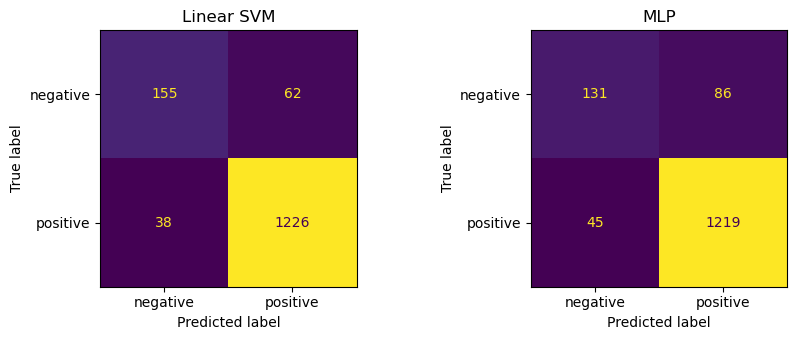

In [15]:
summary = pd.DataFrame([
    {'Model':'Linear SVM', 'Validation accuracy':accuracy_score(y_va,pred_svm),
     'Macro F1':f1_score(y_va,pred_svm,average='macro'),
     'Negative F1':f1_score(y_va,pred_svm,pos_label=0), 'Train seconds':svm_seconds},
    {'Model':'MLP (TF-IDF + SVD)', 'Validation accuracy':accuracy_score(y_va,pred_mlp),
     'Macro F1':f1_score(y_va,pred_mlp,average='macro'),
     'Negative F1':f1_score(y_va,pred_mlp,pos_label=0), 'Train seconds':mlp_seconds}
])
display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9,3.5))
for ax, name, pred in zip(axes, ['Linear SVM','MLP'], [pred_svm,pred_mlp]):
    ConfusionMatrixDisplay.from_predictions(y_va, pred, labels=[0,1],
                                            display_labels=['negative','positive'], ax=ax,
                                            colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


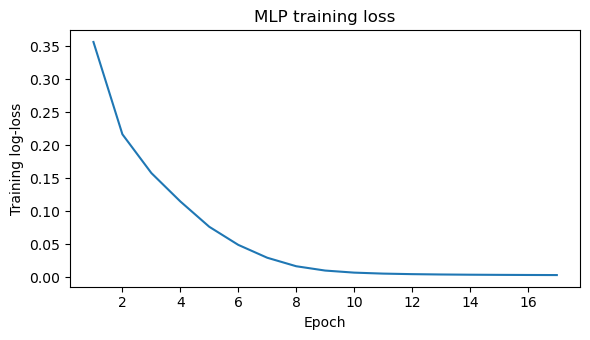

Saved to: C:\Users\jayce\IE4483-sentiment-project-main\results\part_b


In [17]:
history = mlp.named_steps['mlpclassifier'].loss_curve_
plt.figure(figsize=(6,3.5))
plt.plot(range(1,len(history)+1), history)
plt.xlabel('Epoch'); plt.ylabel('Training log-loss'); plt.title('MLP training loss')
plt.tight_layout(); plt.show()
out = ROOT / 'results' / 'part_b'
out.mkdir(parents=True, exist_ok=True)
summary.to_csv(out / 'svm_mlp_validation_metrics.csv', index=False)
with open(out / 'model_config.json', 'w', encoding='utf-8') as f:
    json.dump({'seed':SEED, 'split': 'stratified 80/20',
               'tfidf': {'lowercase':True,'stop_words':'english','ngram_range':[1,2],
                         'min_df':2,'max_features':20000},
               'svm': {'C':1.0,'class_weight':'balanced','max_iter':5000},
               'mlp':{'svd_features':n_components,'hidden_layers':[128,64],
                      'alpha':0.001,'learning_rate':0.001,'batch_size':64,
                      'early_stopping':True}}, f, indent=2)
dump({'vectorizer': vectorizer, 'svm':svm, 'mlp':mlp}, out / 'validation_models.joblib')
print('Saved to:', out)


# (b) Architecture Diagrams
Diagrams show the implementation pipeline. Linear SVM uses TF-IDF directly, whereas MLP uses TruncatedSVD and StandardScalar before 2 hidden layers.

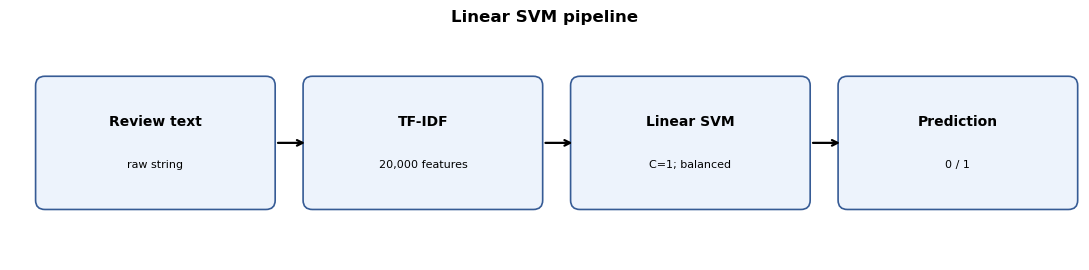

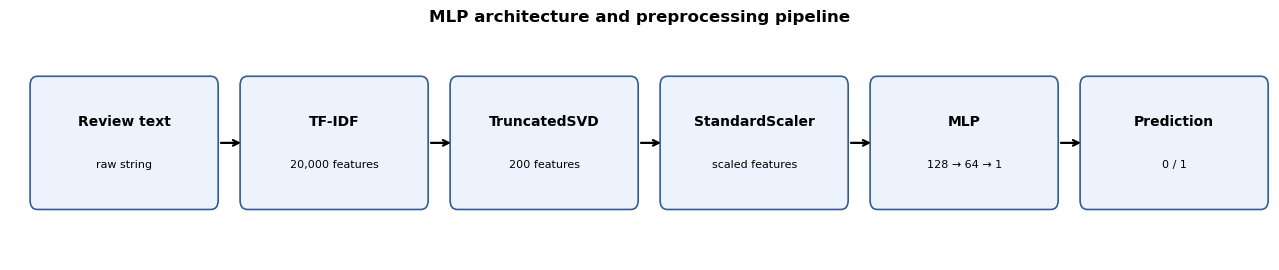

In [19]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def pipeline_figure(items, title, filename):
    fig, ax = plt.subplots(figsize=(max(11, 2.15 * len(items)), 2.8))
    ax.set_xlim(0, len(items) * 2.3)
    ax.set_ylim(0, 2)
    ax.axis('off')
    for i, (label, detail) in enumerate(items):
        x = 0.3 + i * 2.3
        patch = FancyBboxPatch((x, 0.52), 1.9, 1.0,
                               boxstyle='round,pad=0.08', linewidth=1.2,
                               facecolor='#edf3fc', edgecolor='#365b95')
        ax.add_patch(patch)
        ax.text(x+0.95, 1.2, label, ha='center', va='center', fontsize=10, weight='bold')
        ax.text(x+0.95, 0.83, detail, ha='center', va='center', fontsize=8)
        if i < len(items)-1:
            ax.annotate('', xy=(x+2.26, 1.02), xytext=(x+1.98, 1.02),
                        arrowprops=dict(arrowstyle='->', lw=1.6))
    ax.set_title(title, weight='bold', fontsize=12)
    fig.tight_layout()
    fig.savefig(out / filename, dpi=180, bbox_inches='tight')
    plt.show()

out = ROOT / 'results' / 'part_b'
out.mkdir(parents=True, exist_ok=True)
pipeline_figure([
    ('Review text', 'raw string'), ('TF-IDF', f'{X_tr.shape[1]:,} features'),
    ('Linear SVM', 'C=1; balanced'), ('Prediction', '0 / 1')
], 'Linear SVM pipeline', 'svm_architecture.png')
pipeline_figure([
    ('Review text', 'raw string'), ('TF-IDF', f'{X_tr.shape[1]:,} features'),
    ('TruncatedSVD', f'{n_components} features'), ('StandardScaler', 'scaled features'),
    ('MLP', '128 → 64 → 1'), ('Prediction', '0 / 1')
], 'MLP architecture and preprocessing pipeline', 'mlp_architecture.png')

# (c) Comparing parameters
We used the same training/validation split for each comparison. For SVM, we varied C and measured the validation accuracy, macro f1 and negative class f1. For MLP, we varied the size of the hidden layers and regularisation alpha, while other settings are fixed. 

In [26]:
# SVM regularisation
svm_rows = []
for C in [0.01, 0.1, 1.0, 10.0]:
    candidate = LinearSVC(C=C, class_weight='balanced', random_state=SEED, max_iter=10000)
    start = time.perf_counter()
    candidate.fit(X_tr, y_tr)
    pred = candidate.predict(X_va)
    svm_rows.append({'C': C, 'Accuracy': accuracy_score(y_va, pred),
                     'Macro F1': f1_score(y_va, pred, average='macro'),
                     'Negative F1': f1_score(y_va, pred, pos_label=0),
                     'Train seconds': time.perf_counter()-start})
svm_tuning = pd.DataFrame(svm_rows).sort_values('Macro F1', ascending=False)
display(svm_tuning.round(4))
svm_tuning.to_csv(out / 'svm_hyperparameter_comparison.csv', index=False)
BEST_SVM_C = float(svm_tuning.iloc[0]['C'])
print('Chosen SVM C (highest validation macro-F1):', BEST_SVM_C)

,C,Accuracy,Macro F1,Negative F1,Train seconds
2,1.00,0.9325,0.8585,0.7561,0.0901
3,10.00,0.9298,0.8471,0.7347,0.2833
1,0.10,0.9102,0.8355,0.7246,0.0397
0,0.01,0.8764,0.7931,0.6617,0.0284


Chosen SVM C (highest validation macro-F1): 1.0


In [25]:
# For MLP
mlp_rows = []
for hidden in [(64,), (128, 64), (128, 128)]:
    for alpha in [0.0001, 0.001]:
        candidate = make_pipeline(
            TruncatedSVD(n_components=n_components, random_state=SEED),
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=hidden, activation='relu', solver='adam',
                          alpha=alpha, learning_rate_init=0.001, batch_size=64,
                          early_stopping=True, validation_fraction=0.15,
                          n_iter_no_change=10, max_iter=150, random_state=SEED))
        start = time.perf_counter()
        candidate.fit(X_tr, y_tr)
        pred = candidate.predict(X_va)
        mlp_rows.append({'Hidden layers': str(hidden), 'Alpha': alpha,
                         'Accuracy': accuracy_score(y_va, pred),
                         'Macro F1': f1_score(y_va, pred, average='macro'),
                         'Negative F1': f1_score(y_va, pred, pos_label=0),
                         'Train seconds': time.perf_counter()-start})
mlp_tuning = pd.DataFrame(mlp_rows).sort_values('Macro F1', ascending=False)
display(mlp_tuning.round(4))
mlp_tuning.to_csv(out / 'mlp_hyperparameter_comparison.csv', index=False)
print('Best measured MLP configuration:', mlp_tuning.iloc[0][['Hidden layers', 'Alpha']].to_dict())

,Hidden layers,Alpha,Accuracy,Macro F1,Negative F1,Train seconds
2,"(128, 64)",0.0001,0.9142,0.8137,0.6768,4.1032
3,"(128, 64)",0.0010,0.9115,0.8078,0.6667,4.8044
1,"(64,)",0.0010,0.9136,0.8068,0.6632,3.0072
5,"(128, 128)",0.0010,0.9109,0.8051,0.6615,4.8366
0,"(64,)",0.0001,0.9142,0.8034,0.6558,2.8492
4,"(128, 128)",0.0001,0.9061,0.7987,0.6516,4.8672


Best measured MLP configuration: {'Hidden layers': '(128, 64)', 'Alpha': 0.0001}


# (d) Test predictions
We are going to test both classifiers (SVM and MLP) on the test dataset

## Firstly, we need to measure both classifiers on the labelled validation subset first
We did a 80/20 split and fit TF-IDF on the TRAINING PORTION ONLY. This provides us a fair labelled dataset comparison before applying both classifiers
to the unlabelled test set

In [40]:
X_tr_text, X_val_text, y_tr, y_val = train_test_split(
    train_df['reviews'].fillna('').astype(str), train_df['sentiments'].astype(int),
    test_size=0.2, random_state=SEED, stratify=train_df['sentiments']
)
val_tfidf = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1,2), min_df=2, max_features=20000)
X_tr = val_tfidf.fit_transform(X_tr_text)
X_val = val_tfidf.transform(X_val_text)

val_svm = LinearSVC(C=1.0, class_weight='balanced', random_state=SEED, max_iter=5000)
val_svm.fit(X_tr, y_tr)
pred_svm_val = val_svm.predict(X_val)

n_components = min(200, X_tr.shape[0]-1, X_tr.shape[1]-1)
val_mlp = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(128,64), activation='relu', solver='adam',
                  alpha=0.001, learning_rate_init=0.001, batch_size=64,
                  early_stopping=True, validation_fraction=0.15,
                  n_iter_no_change=10, max_iter=150, random_state=SEED)
)
val_mlp.fit(X_tr, y_tr)
pred_mlp_val = val_mlp.predict(X_val)

validation_results = pd.DataFrame([
    {'Model':'Linear SVM', 'Validation accuracy':accuracy_score(y_val, pred_svm_val),
     'Validation macro-F1':f1_score(y_val, pred_svm_val, average='macro')},
    {'Model':'MLP (TF-IDF + SVD)', 'Validation accuracy':accuracy_score(y_val, pred_mlp_val),
     'Validation macro-F1':f1_score(y_val, pred_mlp_val, average='macro')}
])
display(validation_results.round(4))
validation_results.to_csv('both_models_validation_comparison.csv', index=False)
for name, pred in [('SVM',pred_svm_val), ('MLP',pred_mlp_val)]:
    print('\n',name,'VALIDATION classification report')
    print(classification_report(y_val,pred,labels=[0,1],target_names=['Negative','Positive'],zero_division=0))

,Model,Validation accuracy,Validation macro-F1
0,Linear SVM,0.9325,0.8585
1,MLP (TF-IDF + SVD),0.9115,0.8078



 SVM VALIDATION classification report
              precision    recall  f1-score   support

    Negative       0.80      0.71      0.76       217
    Positive       0.95      0.97      0.96      1264

    accuracy                           0.93      1481
   macro avg       0.88      0.84      0.86      1481
weighted avg       0.93      0.93      0.93      1481


 MLP VALIDATION classification report
              precision    recall  f1-score   support

    Negative       0.74      0.60      0.67       217
    Positive       0.93      0.96      0.95      1264

    accuracy                           0.91      1481
   macro avg       0.84      0.78      0.81      1481
weighted avg       0.91      0.91      0.91      1481



## Secondly, train both classifiers using full training dataset, and used both models to predict the sentiments of the reviews in test dataset

In [51]:
full_tfidf = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1,2), min_df=2, max_features=20000)
X_full = full_tfidf.fit_transform(train_df['reviews'].fillna('').astype(str))
X_test = full_tfidf.transform(test_df['reviews'].fillna('').astype(str))
y_full = train_df['sentiments'].astype(int)

final_svm = LinearSVC(C=1.0, class_weight='balanced', random_state=SEED, max_iter=5000)
final_svm.fit(X_full, y_full)
svm_test_pred = final_svm.predict(X_test)

final_mlp = make_pipeline(
    TruncatedSVD(n_components=min(200, X_full.shape[0]-1, X_full.shape[1]-1), random_state=SEED),
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(128,64), activation='relu', solver='adam',
                  alpha=0.001, learning_rate_init=0.001, batch_size=64,
                  early_stopping=True, validation_fraction=0.15,
                  n_iter_no_change=10, max_iter=150, random_state=SEED)
)
final_mlp.fit(X_full, y_full)
mlp_test_pred = final_mlp.predict(X_test)
assert len(svm_test_pred)==len(mlp_test_pred)==len(test_df)

# Separate files for both classifiers; choose one for the official submission.
for name, preds in [('SVM',svm_test_pred),('MLP',mlp_test_pred)]:
    pd.DataFrame({'reviews':test_df.reviews, 'predictions':preds.astype(int)}).to_csv(f'submission_{name}.csv',index=False)
print('Saved submission_SVM.csv and submission_MLP.csv')

Saved submission_SVM.csv and submission_MLP.csv


## Next, compare the test predictions of the 2 classifiers. SVM classifier prediction vs MLP classifier prediction

In [56]:
comparison = pd.DataFrame({
    'review_index':np.arange(len(test_df)), 'reviews':test_df['reviews'],
    'svm_prediction':svm_test_pred.astype(int), 'mlp_prediction':mlp_test_pred.astype(int)
})
comparison['agree'] = comparison['svm_prediction']==comparison['mlp_prediction']
comparison.to_csv('SVM_MLP_test_comparison.csv',index=False)
comparison.loc[~comparison.agree].to_csv('SVM_MLP_test_disagreements.csv',index=False)

print('Test rows:',len(comparison))
print('Agreement:', f'{comparison.agree.mean():.2%}', '(',int(comparison.agree.sum()),'of',len(comparison),')')
print('Disagreements:',int((~comparison.agree).sum()))
print('\nTest-set predicted class counts (not correctness):')
display(pd.DataFrame({'SVM':pd.Series(svm_test_pred).value_counts(), 'MLP':pd.Series(mlp_test_pred).value_counts()}).rename(index={0:'Negative (0)',1:'Positive (1)'}).fillna(0).astype(int))
print('\nTest prediction cross-tabulation:')
display(pd.crosstab(comparison.svm_prediction,comparison.mlp_prediction,rownames=['SVM'],colnames=['MLP']))
print('\nSample disagreements:')
display(comparison.loc[~comparison.agree].head(10))

Test rows: 1851
Agreement: 91.84% ( 1700 of 1851 )
Disagreements: 151

Test-set predicted class counts (not correctness):


,SVM,MLP
Positive (1),1583,1638
Negative (0),268,213



Test prediction cross-tabulation:


MLP,0,1
SVM,,
0,165,103
1,48,1535



Sample disagreements:


,review_index,reviews,svm_prediction,mlp_prediction,agree
8,8,"There was no picture of this selection, so I g...",0,1,False
13,13,With the proper sizing of my foot by a podiatr...,0,1,False
39,39,"Plush, soft terrycloth fabric with padded inne...",0,1,False
40,40,I have sweaty feet. :( Using standard cotton ...,0,1,False
65,65,These bras do not hold up very well. I started...,0,1,False
74,74,The soles of these shoes are very comfortable ...,0,1,False
82,82,"These are adorable pumps, it's too bad I could...",0,1,False
99,99,"I liked this bra for a while, it had nice shap...",0,1,False
142,142,I was pleased with all purchase. I did not fe...,0,1,False
152,152,This is ideal for wearing layers of clothing o...,1,0,False


# (e) Error analysis